# 1. Combined Cycle Power Plant Data Set

## (a) Import Data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

In [5]:
data = pd.read_excel("Folds5x2_pp.xlsx", sheet_name="Sheet1")
data.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## (b) Exploring the Data

### i

In [6]:
data.shape
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


Rows: 9568  
Colims: 5  
Each row represents one hourly observation collected from the power plant.  
AT, V, AP, RH are four predictor variables.  
PE is response variable.

### ii Make pairwise scatterplots

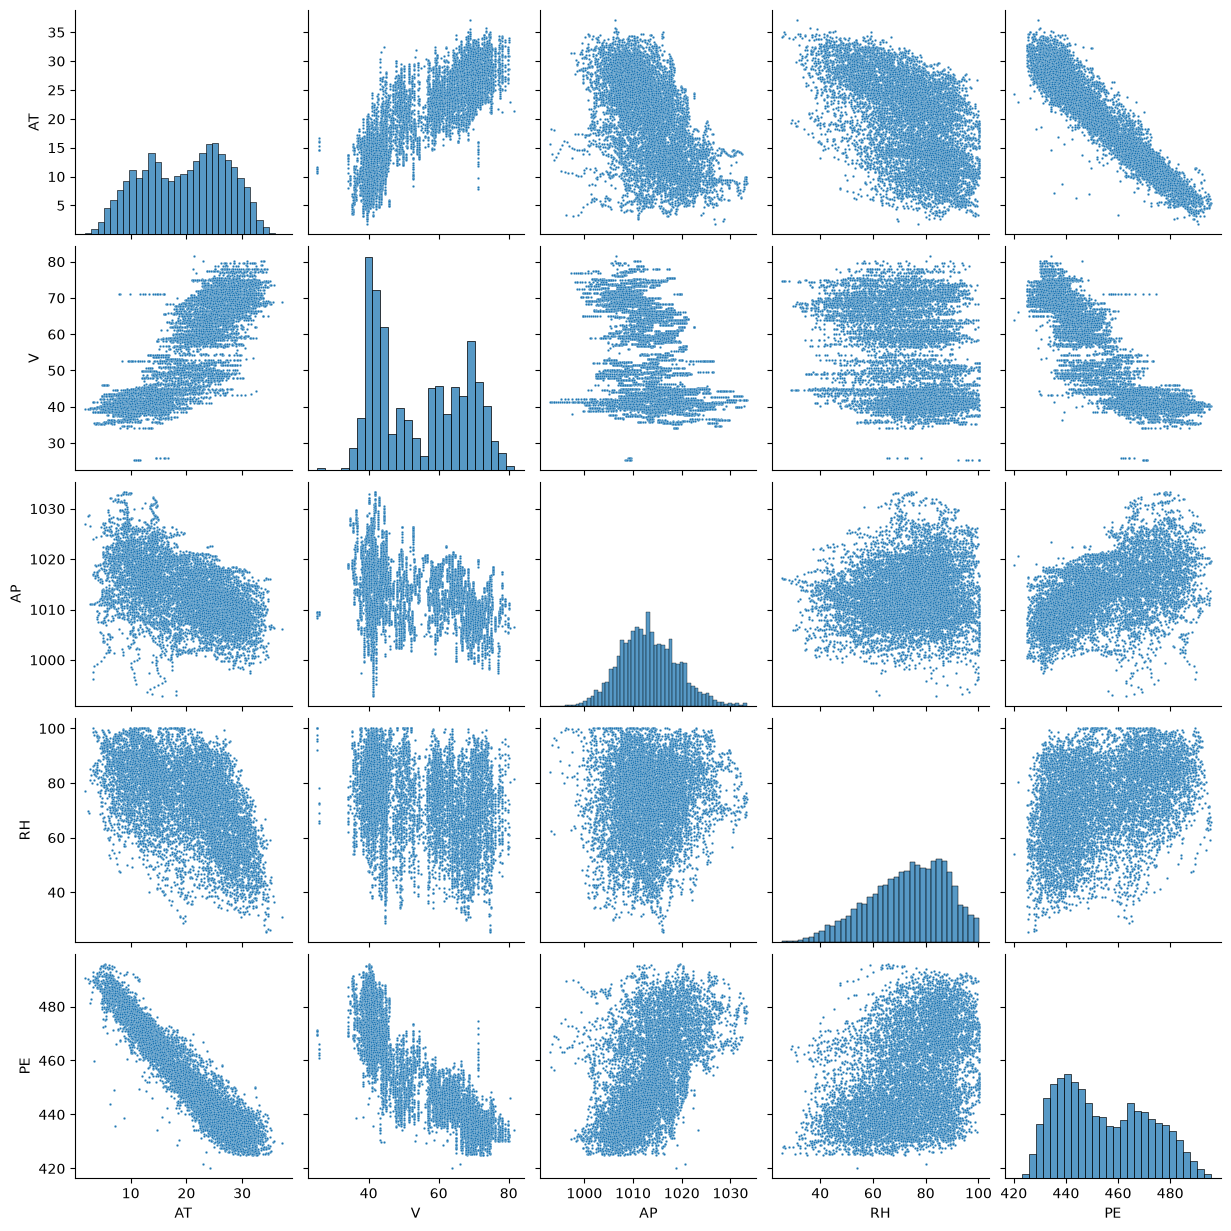

In [7]:
sns.pairplot(data, plot_kws={"s": 3})
plt.show()

PE and AT: Negatively Related  
PE and V: Negatively Related  
PE and AP: Positively Related  
PE and RH: Positively Related

### iii

In [8]:
summary = pd.DataFrame({
    "Mean": data.mean(),
    "Median": data.median(),
    "Range": data.max() - data.min(),
    "First Quartile": data.quantile(0.25),
    "Third Quartile": data.quantile(0.75),
    "IQR": data.quantile(0.75) - data.quantile(0.25)
})
summary.round(2)

,Mean,Median,Range,First Quartile,Third Quartile,IQR
AT,19.65,20.34,35.30,13.51,25.72,12.21
V,54.31,52.08,56.20,41.74,66.54,24.80
AP,1013.26,1012.94,40.41,1009.10,1017.26,8.16
RH,73.31,74.97,74.60,63.33,84.83,21.50
PE,454.37,451.55,75.50,439.75,468.43,28.68


## (c) Simple Linear Regression Model

In [9]:
predictors = ["AT", "V", "AP", "RH"]
results = []
for predictor in predictors:
    X = sm.add_constant(data[predictor])
    y = data["PE"]
    model = sm.OLS(y, X).fit()
    results.append({
        "Predictor": predictor,
        "Coefficient": model.params[predictor],
        "P-value": model.pvalues[predictor],
        "R-squared": model.rsquared
    })
simple_results = pd.DataFrame(results)
simple_results

,Predictor,Coefficient,P-value,R-squared
0,AT,-2.171320,0.0,0.898948
1,V,-1.168135,0.0,0.756518
2,AP,1.489872,0.0,0.268769
3,RH,0.455650,0.0,0.151939


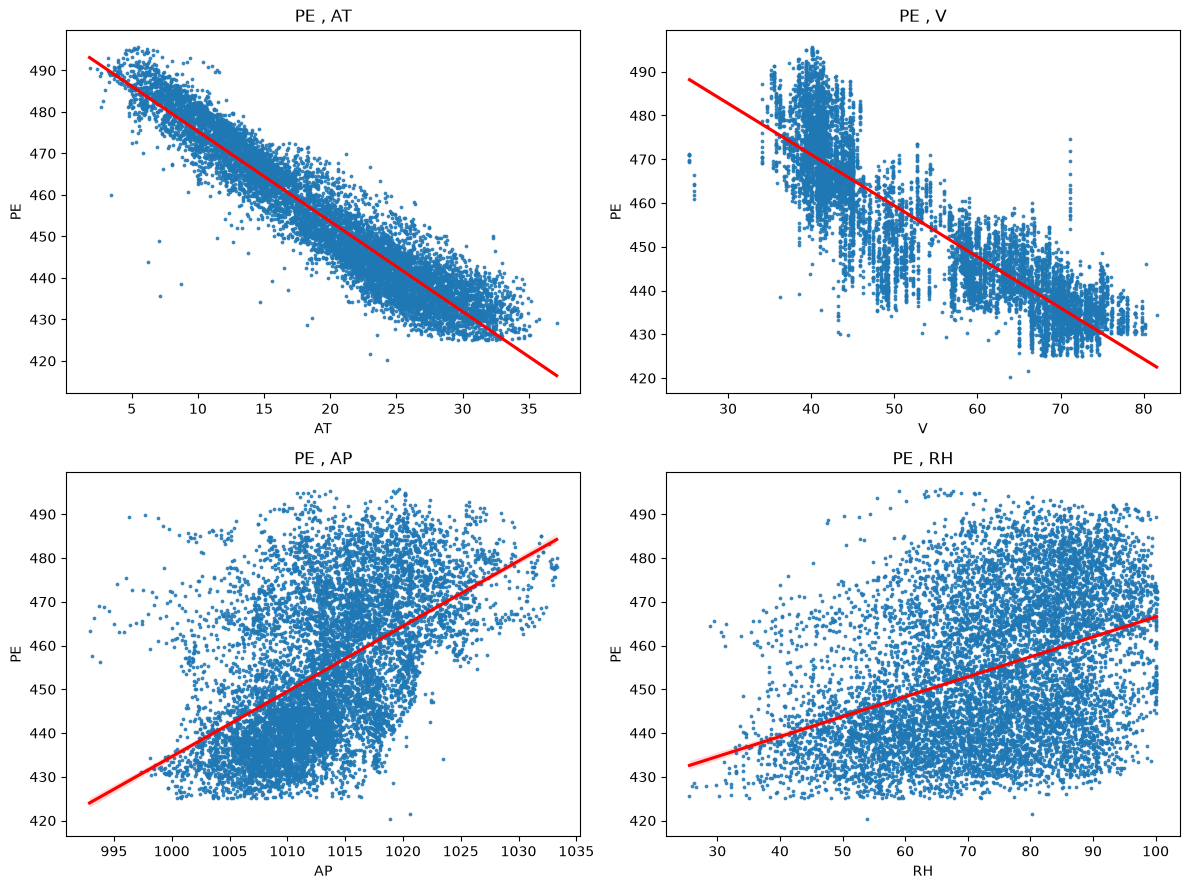

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for predictor, ax in zip(predictors, axes.flatten()):
    sns.regplot(
        data=data,
        x=predictor,
        y="PE",
        scatter_kws={"s": 3},
        line_kws={"color": "red"},
        ax=ax
    )
    ax.set_title(f"PE , {predictor}")
plt.tight_layout()
plt.show()

In [11]:
for predictor in predictors:
    X = sm.add_constant(data[predictor])
    model = sm.OLS(data["PE"], X).fit()
    studentized_residuals = model.get_influence().resid_studentized_external
    outliers = data[np.abs(studentized_residuals) > 3]
    
    print(predictor, ":", len(outliers), "possible outliers")

AT : 42 possible outliers
V : 33 possible outliers
AP : 30 possible outliers
RH : 2 possible outliers


All four predictors have statistically significant relationships with PE.  
AT is the most significant.  
There are a small number of possible outliers, but they have not been eliminated.

## (d) Multiple Linear Regression

In [12]:
X = data[["AT", "V", "AP", "RH"]]
y = data["PE"]

X = sm.add_constant(X)
multiple_model = sm.OLS(y, X).fit()
multiple_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Thu, 24 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:26:11   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.000     435.500     473.718
AT            -1.9775      0.015   -129.342      0.000      -2.007      -1.948
V             -0.2339      0.007    -32.122      0.000      -0.248      -0.220
AP             0.0621      0.009      6.564      0.000       0.044       0.081
RH            -0.1581      0.004    -37.918      0.000      -0.166      -0.150
==============================================================================
Omnibus:                      892.002   Durbin-Watson:                   2.033
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4086.777
Skew:                          -0.352   Prob(JB):                         0.00
Kurtosis:                       6.123   Cond. No.                     2.13e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.13e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

R-squard is 92.9%.  
Four P-values are below 0.05.
So all four predictors can be rejected.

## (e) Compare 1c with 1d

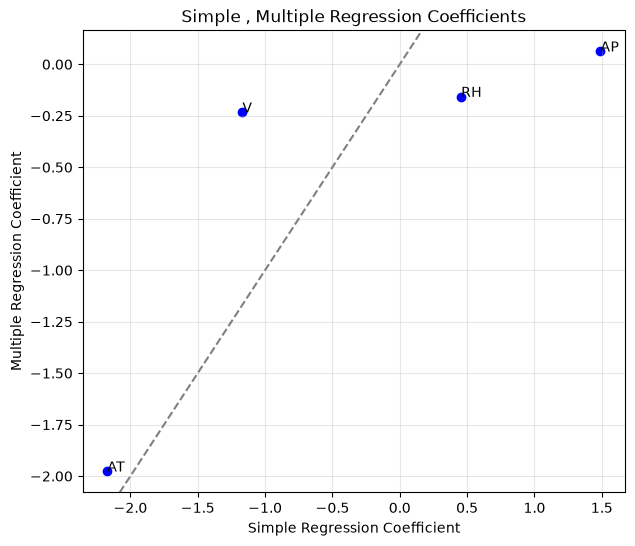

In [13]:
simple_coef = simple_results.set_index("Predictor")["Coefficient"]
multiple_coef = multiple_model.params[predictors]
coef_comparison = pd.DataFrame({
    "Simple Regression": simple_coef,
    "Multiple Regression": multiple_coef
})
coef_comparison
plt.figure(figsize=(7, 6))
plt.scatter(
    coef_comparison["Simple Regression"],
    coef_comparison["Multiple Regression"],
    color="blue"
)
for predictor in predictors:
    plt.text(
        coef_comparison.loc[predictor, "Simple Regression"],
        coef_comparison.loc[predictor, "Multiple Regression"],
        predictor
    )
plt.axline((0, 0), slope=1, color="gray", linestyle="--")
plt.xlabel("Simple Regression Coefficient")
plt.ylabel("Multiple Regression Coefficient")
plt.title("Simple , Multiple Regression Coefficients")
plt.grid(alpha=0.3)
plt.show()

AT is similar, V and AP reduce, RH changes from positive to negative.

## (f) Fit Model

In [14]:
polynomial_models = {}
polynomial_results = []

for predictor in predictors:
    X_poly = pd.DataFrame({
        predictor: data[predictor],
        predictor + "^2": data[predictor] ** 2,
        predictor + "^3": data[predictor] ** 3
    })
    X_poly = sm.add_constant(X_poly)
    model = sm.OLS(data["PE"], X_poly).fit()
    polynomial_models[predictor] = model
    polynomial_results.append({
        "Predictor": predictor,
        "Linear p-value": model.pvalues[predictor],
        "Quadratic p-value": model.pvalues[predictor + "^2"],
        "Cubic p-value": model.pvalues[predictor + "^3"]
    })

polynomial_results = pd.DataFrame(polynomial_results)
polynomial_results

,Predictor,Linear p-value,Quadratic p-value,Cubic p-value
0,AT,7.898147e-07,8.833045e-73,3.652185e-110
1,V,2.526589e-05,7.684969e-01,1.373489e-02
2,AP,4.502735e-17,3.666705e-17,8.264146e-18
3,RH,3.772510e-04,9.395430e-06,1.440279e-05


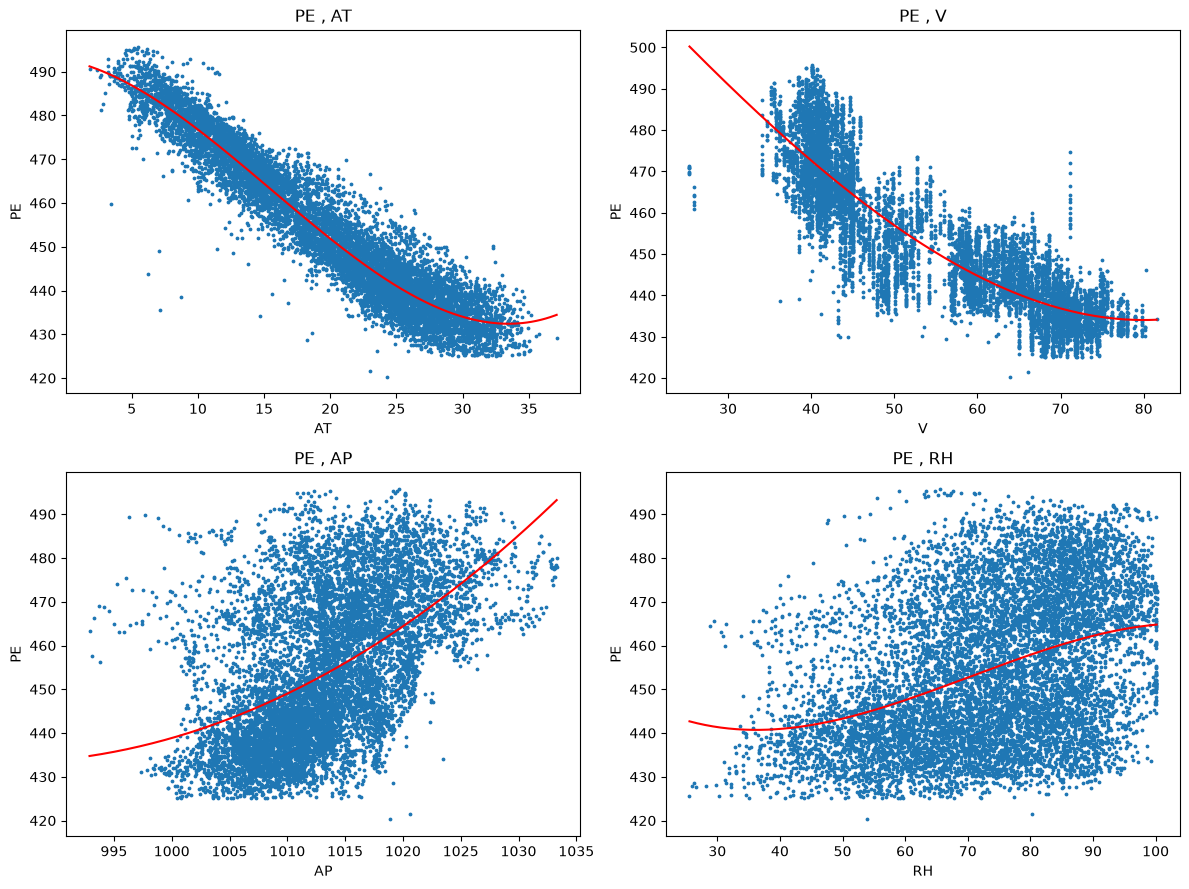

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for predictor, ax in zip(predictors, axes.flatten()):
    x_values = np.linspace(
        data[predictor].min(),
        data[predictor].max(),
        300
    )
    prediction_data = pd.DataFrame({
        "const": 1,
        predictor: x_values,
        predictor + "^2": x_values ** 2,
        predictor + "^3": x_values ** 3
    })
    predicted_pe = polynomial_models[predictor].predict(prediction_data)
    ax.scatter(data[predictor], data["PE"], s=3)
    ax.plot(x_values, predicted_pe, color="red")
    ax.set_xlabel(predictor)
    ax.set_ylabel("PE")
    ax.set_title(f"PE , {predictor}")

plt.tight_layout()
plt.show()

## (g) Full Linear Regression Model

In [16]:
import statsmodels.formula.api as smf
interaction_model = smf.ols(
    "PE ~ (AT + V + AP + RH) ** 2",
    data=data
).fit()
interaction_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Thu, 24 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:26:12   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.000     531.631     839.934
AT            -4.3470      2.373     -1.832      0.067      -8.999       0.305
V             -7.6749      1.351     -5.682      0.000     -10.323      -5.027
AP            -0.1524      0.077     -1.983      0.047      -0.303      -0.002
RH             1.5709      0.773      2.031      0.042       0.055       3.087
AT:V           0.0210      0.001     23.338      0.000       0.019       0.023
AT:AP          0.0018      0.002      0.752      0.452      -0.003       0.006
AT:RH         -0.0052      0.001     -6.444      0.000      -0.007      -0.004
V:AP           0.0068      0.001      5.135      0.000       0.004       0.009
V:RH           0.0008      0.000      1.716      0.086      -0.000       0.002
AP:RH         -0.0016      0.001     -2.125      0.034      -0.003      -0.000
==============================================================================
Omnibus:                     1454.609   Durbin-Watson:                   2.030
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9170.848
Skew:                          -0.574   Prob(JB):                         0.00
Kurtosis:                       7.657   Cond. No.                     1.70e+08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.7e+08. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [17]:
interaction_pvalues = interaction_model.pvalues[
    interaction_model.pvalues.index.str.contains(":")
]
interaction_pvalues
interaction_pvalues[interaction_pvalues < 0.05]

AT:V     3.333358e-117
AT:RH     1.216944e-10
V:AP      2.877026e-07
AP:RH     3.360557e-02
dtype: float64

AT:V, AT:RH, V:AP, AP:RH have, V:RH dosen't have.

## (h) Improve Model

In [18]:
train_data, test_data = train_test_split(
    data,
    test_size=0.30,
    random_state=1
)
linear_model = smf.ols(
    "PE ~ AT + V + AP + RH",
    data=train_data
).fit()

linear_train_pred = linear_model.predict(train_data)
linear_test_pred = linear_model.predict(test_data)

linear_train_mse = mean_squared_error(
    train_data["PE"], linear_train_pred
)

linear_test_mse = mean_squared_error(
    test_data["PE"], linear_test_pred
)

print("Training MSE:", linear_train_mse)
print("Test MSE:", linear_test_mse)

Training MSE: 20.766119761450934
Test MSE: 20.77747810688455


In [19]:
full_formula = """
PE ~ AT + V + AP + RH
+ I(AT ** 2) + I(V ** 2) + I(AP ** 2) + I(RH ** 2)
+ AT:V + AT:AP + AT:RH + V:AP + V:RH + AP:RH
"""
full_model = smf.ols(full_formula, data=train_data).fit()
full_model.summary()
full_model.pvalues[full_model.pvalues > 0.05]

AT           0.301052
I(V ** 2)    0.312410
AT:AP        0.730882
V:AP         0.065201
V:RH         0.535398
dtype: float64

In [20]:
reduced_formula = """
PE ~ AT + V + AP + RH
+ I(AT ** 2) + I(AP ** 2) + I(RH ** 2)
+ AT:V + AT:AP + AT:RH + V:AP + AP:RH
"""
reduced_model = smf.ols(
    reduced_formula,
    data=train_data
).fit()
reduced_model.summary()
reduced_model.pvalues[reduced_model.pvalues > 0.05]

AT       0.193002
V        0.051779
AT:AP    0.560723
V:AP     0.094230
dtype: float64

In [21]:
reduced_train_pred = reduced_model.predict(train_data)
reduced_test_pred = reduced_model.predict(test_data)
reduced_train_mse = mean_squared_error(
    train_data["PE"], reduced_train_pred
)
reduced_test_mse = mean_squared_error(
    test_data["PE"], reduced_test_pred
)
mse_results = pd.DataFrame({
    "Model": ["Linear Model", "Reduced Nonlinear Model"],
    "Training MSE": [linear_train_mse, reduced_train_mse],
    "Test MSE": [linear_test_mse, reduced_test_mse]
})
mse_results.round(2)

,Model,Training MSE,Test MSE
0,Linear Model,20.77,20.78
1,Reduced Nonlinear Model,18.06,18.23


## (i) KNN Regression

In [22]:
features = ["AT", "V", "AP", "RH"]
X_train = train_data[features]
y_train = train_data["PE"]
X_test = test_data[features]
y_test = test_data["PE"]

In [23]:
k_values = range(1, 101)
raw_train_mse = []
raw_test_mse = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    train_pred = knn.predict(X_train)
    test_pred = knn.predict(X_test)
    raw_train_mse.append(mean_squared_error(y_train, train_pred))
    raw_test_mse.append(mean_squared_error(y_test, test_pred))

best_raw_index = np.argmin(raw_test_mse)
best_raw_k = list(k_values)[best_raw_index]

print("Best k for raw features:", best_raw_k)
print("Training MSE:", raw_train_mse[best_raw_index])
print("Test MSE:", raw_test_mse[best_raw_index])

Best k for raw features: 5
Training MSE: 10.552961493205913
Test MSE: 15.704821203761764


In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_train_mse = []
scaled_test_mse = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_pred = knn.predict(X_train_scaled)
    test_pred = knn.predict(X_test_scaled)
    scaled_train_mse.append(mean_squared_error(y_train, train_pred))
    scaled_test_mse.append(mean_squared_error(y_test, test_pred))

best_scaled_index = np.argmin(scaled_test_mse)
best_scaled_k = list(k_values)[best_scaled_index]

print("Best k for standardized features:", best_scaled_k)
print("Training MSE:", scaled_train_mse[best_scaled_index])
print("Test MSE:", scaled_test_mse[best_scaled_index])

Best k for standardized features: 4
Training MSE: 8.738516436464089
Test MSE: 14.070606067136888


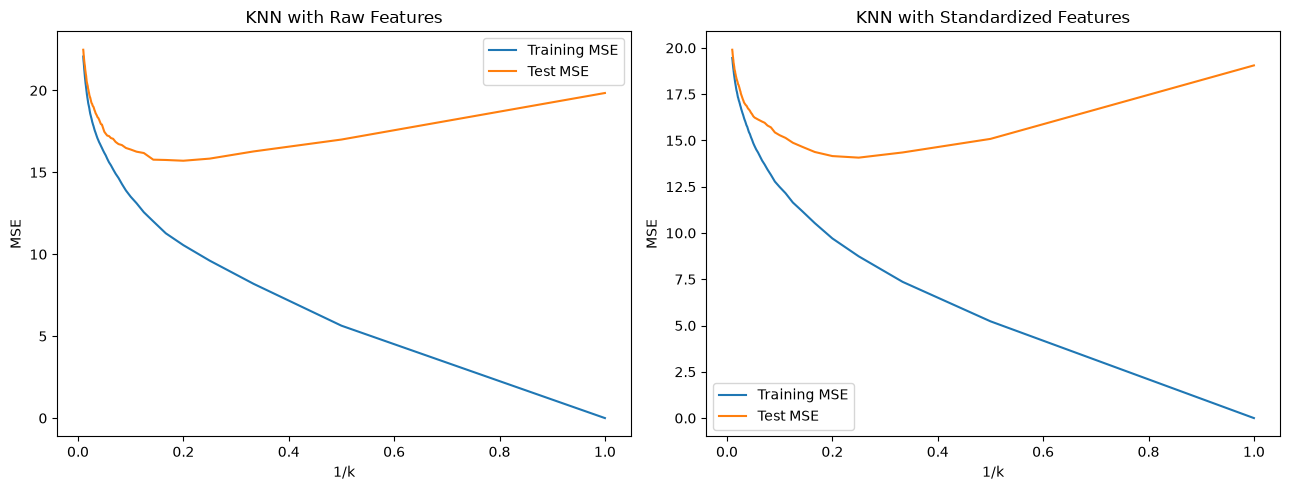

In [25]:
inverse_k = [1 / k for k in k_values]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(inverse_k, raw_train_mse, label="Training MSE")
axes[0].plot(inverse_k, raw_test_mse, label="Test MSE")
axes[0].set_xlabel("1/k")
axes[0].set_ylabel("MSE")
axes[0].set_title("KNN with Raw Features")
axes[0].legend()
axes[1].plot(inverse_k, scaled_train_mse, label="Training MSE")
axes[1].plot(inverse_k, scaled_test_mse, label="Test MSE")
axes[1].set_xlabel("1/k")
axes[1].set_ylabel("MSE")
axes[1].set_title("KNN with Standardized Features")
axes[1].legend()

plt.tight_layout()
plt.show()

## (j) Comparison of KNN with Linear Regression

Reduced Nonlinear Regression：  
Training MSE：18.06  
Test MSE：18.23  

Standardized KNN：  
Training MSE：8.74  
Test MSE：14.07  

KNN model has lower test MSE than the reduced nonlinear regression model. KNN has better predictive performance.

# 2. ISLR 2.4.1

(a)  
Better.  
Large sample size means low probability of overfitting, and it can capture more complex relationships.  

(b)  
Worse.   
Many predictors and few observations means high probability of overfitting, as well as high variance.  

(c)  
Better.  
By capturing highly nonlinear relationships, the performance of this method can be improved.   

(d)    
Worse.  
When the variance is too high, the fitting result will be affected by noise, leading to overfitting.

# 3. ISLR 2.4.7

## a

In [30]:
knn_data = pd.DataFrame({
    "X1": [0, 2, 0, 0, -1, 1],
    "X2": [3, 0, 1, 1, 0, 1],
    "X3": [0, 0, 3, 2, 1, 1],
    "Y": ["Red", "Red", "Red", "Green", "Green", "Red"]
})
knn_data.index = range(1, 7)
knn_data.index.name = "Obs."
test_point = np.array([0, 0, 0])
knn_data["Distance"] = np.sqrt(
    (knn_data["X1"] - test_point[0]) ** 2
    + (knn_data["X2"] - test_point[1]) ** 2
    + (knn_data["X3"] - test_point[2]) ** 2
)
knn_data

,X1,X2,X3,Y,Distance
Obs.,,,,,
1,0,3,0,Red,3.000000
2,2,0,0,Red,2.000000
3,0,1,3,Red,3.162278
4,0,1,2,Green,2.236068
5,-1,0,1,Green,1.414214
6,1,1,1,Red,1.732051


b  
K=1, Obs.5 is the closet, its distance is 1.414. Y is Green.

c  
K=3, the three closet are Obs.5,6,2. Y are Green, Red and Red, so it is Red.

d  
K shoudl be smaller, which is better able to capture highly nonlinear pattern.